<a href="https://colab.research.google.com/github/MeriemHakkak/Projet-Fin-2-El-Haddioui-Aymane-Hakkak-Meriem/blob/main/Fin_2_El_Haddioui_Aymane_Hakkak_Meriem_Projet_Dow_Jones_rendements_hebdomadaires_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet : peut-on prévoir le rendement hebdomadaire des titres du Dow Jones ?

**Durée estimée :** 3 heures · **Niveau :** premier cycle universitaire, bases de Python, de statistique et de finance

## Objectifs

Ce projet vise à :

1. formuler une question de prévision précise et en justifier l'intérêt financier ;
2. charger un jeu de données public, le documenter et l'explorer graphiquement ;
3. construire des variables explicatives et une cible **sans aucune information future** ;
4. choisir un protocole d'évaluation **chronologique**, adapté aux séries temporelles ;
5. comparer des modèles de régression et de classification à des références simples ;
6. évaluer honnêtement la précision des prévisions et en discuter les limites.

## 1. Question posée et type d'apprentissage

**Question.** Les rendements hebdomadaires passés d'un titre et son prix d'ouverture permettent-ils de prévoir son rendement de la semaine suivante ?

**Intérêt financier.** Un investisseur qui saurait prévoir, même faiblement, le rendement de la semaine suivante pourrait mieux choisir ses titres ou ajuster son exposition. Mais l'**hypothèse d'efficience des marchés** (dans sa forme faible) affirme que les prix passés sont déjà intégrés dans les prix actuels : les rendements passés ne devraient donc pas aider à prévoir les suivants. Ce projet confronte cette hypothèse aux données. Un résultat du type « aucun modèle ne fait mieux que la référence » est un résultat valable, à condition d'être démontré proprement.

Le problème relève de l'**apprentissage supervisé**, avec deux formulations complémentaires :

- **Régression** : la cible est le rendement de la semaine suivante, une valeur réelle exprimée en pourcentage ;
- **Classification binaire** : la cible vaut 1 si le rendement de la semaine suivante est strictement positif (hausse), 0 sinon.

Dans les deux cas, la bonne réponse est connue pour chaque observation (le rendement réellement observé la semaine suivante) : le modèle apprend à partir de paires (entrée, sortie), ce qui le distingue d'un algorithme de partitionnement.

> **Remarque.** En finance, une prévision n'a pas besoin d'être précise pour être utile : deviner la **direction** un peu mieux que le hasard peut suffire. Cet avantage ne vaut toutefois que s'il survit aux coûts de transaction, ce que ce projet ne mesure pas.

## 2. Le jeu de données

Le jeu de données **Dow Jones Index** (Brown, Pelosi et Dirska, 2013) est mis à disposition par le *UCI Machine Learning Repository* (identifiant 312). Il décrit, semaine par semaine, 30 titres de l'indice Dow Jones Industrial Average pendant les deux premiers trimestres de 2011 : 25 semaines × 30 titres = **750 observations**, **16 variables**. Une ligne correspond à un couple (titre, semaine).

| Variable | Type | Description |
|---|---|---|
| `quarter` | catégorielle | Trimestre de 2011 (1 ou 2) |
| `stock` | catégorielle | Symbole boursier du titre (30 titres) |
| `date` | date | Dernier jour de bourse de la semaine |
| `open` | numérique | Prix à l'ouverture, premier jour de la semaine (\$) |
| `high` | numérique | Prix le plus haut de la semaine (\$) |
| `low` | numérique | Prix le plus bas de la semaine (\$) |
| `close` | numérique | Prix de clôture, dernier jour de la semaine (\$) |
| `volume` | numérique | Nombre d'actions échangées pendant la semaine |
| `percent_change_price` | numérique | Variation du prix pendant la semaine, de l'ouverture à la clôture (%) : le **rendement hebdomadaire** |
| `percent_change_volume_over_last_wk` | numérique | Variation du volume par rapport à la semaine précédente (%) |
| `previous_weeks_volume` | numérique | Volume de la semaine précédente |
| `next_weeks_open` | numérique | Prix d'ouverture de la semaine suivante (\$) |
| `next_weeks_close` | numérique | Prix de clôture de la semaine suivante (\$) |
| `percent_change_next_weeks_price` | numérique | Variation du prix pendant la semaine suivante (%) : la **cible** |
| `days_to_next_dividend` | numérique | Nombre de jours avant le prochain dividende |
| `percent_return_next_dividend` | numérique | Rendement du prochain dividende (%) |

Le chargement se fait directement depuis l'URL du dépôt UCI. Si le téléchargement échoue (réseau bloqué), la cellule de chargement lit à la place un fichier `dow_jones_index.data` placé à côté du notebook.

In [ ]:
# Importation des bibliothèques
import io, os, zipfile, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binomtest

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, roc_auc_score,
                             average_precision_score, accuracy_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [ ]:
# Chargement du jeu de données depuis le dépôt UCI (avec repli sur un fichier local)
URLS = [
    "https://archive.ics.uci.edu/static/public/312/dow+jones+index.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00312/dow_jones_index.zip",
]

def charger_dow_jones():
    for url in URLS:
        try:
            requete = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(requete, timeout=30) as reponse:
                archive = zipfile.ZipFile(io.BytesIO(reponse.read()))
            nom = [n for n in archive.namelist() if n.endswith(".data")][0]
            return pd.read_csv(archive.open(nom)), url
        except Exception as erreur:
            print(f"Échec ({type(erreur).__name__}) : {url}")
    if os.path.exists("dow_jones_index.data"):
        return pd.read_csv("dow_jones_index.data"), "fichier local dow_jones_index.data"
    raise FileNotFoundError(
        "Téléchargez dow_jones_index.zip sur https://archive.ics.uci.edu/dataset/312/dow+jones+index, "
        "extrayez dow_jones_index.data à côté du notebook, puis relancez la cellule.")

brut, source = charger_dow_jones()
print("Source :", source)
print("Dimensions :", brut.shape)
brut.head()

Source : https://archive.ics.uci.edu/static/public/312/dow+jones+index.zip
Dimensions : (750, 16)


,quarter,stock,date,open,high,low,close,volume,percent_change_price,percent_change_volume_over_last_wk,previous_weeks_volume,next_weeks_open,next_weeks_close,percent_change_next_weeks_price,days_to_next_dividend,percent_return_next_dividend
0,1,AA,1/7/2011,$15.82,$16.72,$15.78,$16.42,239655616,3.79267,NaN,NaN,$16.71,$15.97,-4.428490,26,0.182704
1,1,AA,1/14/2011,$16.71,$16.71,$15.64,$15.97,242963398,-4.42849,1.380223,239655616.0,$16.19,$15.79,-2.470660,19,0.187852
2,1,AA,1/21/2011,$16.19,$16.38,$15.60,$15.79,138428495,-2.47066,-43.024959,242963398.0,$15.87,$16.13,1.638310,12,0.189994
3,1,AA,1/28/2011,$15.87,$16.63,$15.82,$16.13,151379173,1.63831,9.355500,138428495.0,$16.18,$17.14,5.933250,5,0.185989
4,1,AA,2/4/2011,$16.18,$17.39,$16.18,$17.14,154387761,5.93325,1.987452,151379173.0,$17.33,$17.37,0.230814,97,0.175029


## 3. Première exploration

Avant toute modélisation, on examine la structure des données : types des colonnes, valeurs manquantes et statistiques descriptives. Les prix sont stockés sous forme de texte avec le symbole \$ ; il faut les convertir en nombres avant tout calcul.

In [ ]:
# Types des colonnes et valeurs manquantes
brut.info()
print("\nColonnes contenant des valeurs manquantes :")
print(brut.isna().sum()[lambda s: s > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   quarter                             750 non-null    int64  
 1   stock                               750 non-null    object 
 2   date                                750 non-null    object 
 3   open                                750 non-null    object 
 4   high                                750 non-null    object 
 5   low                                 750 non-null    object 
 6   close                               750 non-null    object 
 7   volume                              750 non-null    int64  
 8   percent_change_price                750 non-null    float64
 9   percent_change_volume_over_last_wk  720 non-null    float64
 10  previous_weeks_volume               720 non-null    float64
 11  next_weeks_open                     750 non-n

In [ ]:
# Conversion des prix (« $15.82 » -> 15.82) et des dates, puis tri par titre et par semaine
df = brut.copy()
colonnes_prix = ["open", "high", "low", "close", "next_weeks_open", "next_weeks_close"]
for c in colonnes_prix:
    df[c] = df[c].astype(str).str.replace(r"[$,]", "", regex=True).astype(float)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["stock", "date"]).reset_index(drop=True)

print("Nombre de titres  :", df["stock"].nunique())
print("Nombre de semaines :", df["date"].nunique())
print("Période            :", df["date"].min().date(), "->", df["date"].max().date())
df.describe().round(2)

Nombre de titres  : 30
Nombre de semaines : 25
Période            : 2011-01-07 -> 2011-06-24


,quarter,date,open,high,low,close,volume,percent_change_price,percent_change_volume_over_last_wk,previous_weeks_volume,next_weeks_open,next_weeks_close,percent_change_next_weeks_price,days_to_next_dividend,percent_return_next_dividend
count,750.00,750,750.00,750.00,750.00,750.00,7.500000e+02,750.00,720.00,7.200000e+02,750.00,750.00,750.00,750.00,750.00
mean,1.52,2011-03-31 23:02:24,53.65,54.67,52.64,53.73,1.175478e+08,0.05,5.59,1.173876e+08,53.70,53.89,0.24,52.53,0.69
min,1.00,2011-01-07 00:00:00,10.59,10.94,10.40,10.52,9.718851e+06,-15.42,-61.43,9.718851e+06,10.52,10.52,-15.42,0.00,0.07
25%,1.00,2011-02-18 00:00:00,29.83,30.63,28.72,30.36,3.086624e+07,-1.29,-19.80,3.067832e+07,30.32,30.46,-1.22,24.00,0.53
50%,2.00,2011-04-01 00:00:00,45.97,46.89,44.80,45.93,5.306088e+07,0.00,0.51,5.294556e+07,46.02,46.12,0.10,47.00,0.68
75%,2.00,2011-05-13 00:00:00,72.72,74.29,71.04,72.67,1.327218e+08,1.65,21.80,1.333230e+08,72.72,72.91,1.85,69.00,0.85
max,2.00,2011-06-24 00:00:00,172.11,173.54,167.82,170.58,1.453439e+09,9.88,327.41,1.453439e+09,172.11,174.54,9.88,336.00,1.56
std,0.50,NaN,32.64,33.22,32.12,32.79,1.584381e+08,2.52,40.54,1.592322e+08,32.78,33.02,2.68,46.34,0.31


**Lecture.** Trois points sont à vérifier dans les sorties ci-dessus.

1. Les valeurs manquantes devraient se limiter à `percent_change_volume_over_last_wk` et `previous_weeks_volume`, pour la première semaine de chaque titre (il n'existe pas de semaine précédente). On attend 30 titres × 25 semaines = 750 lignes.
2. Les échelles des variables sont très différentes : les volumes se chiffrent en millions d'actions, les prix en dizaines ou centaines de dollars, les rendements en pourcents. Une **standardisation** sera nécessaire pour le modèle linéaire.
3. Les rendements hebdomadaires (`percent_change_price`) sont de l'ordre de quelques pourcents : l'essentiel du signal à prévoir est donc de faible amplitude.

## 4. Visualisation des données

### 4.1 La cible : distribution et répartition des classes

La cible de la régression est le rendement de la semaine suivante. Pour la classification, on le transforme en deux classes (hausse ou non). Il faut vérifier si ces classes sont équilibrées : un déséquilibre rendrait l'exactitude trompeuse.

Rendement de la semaine suivante : moyenne = 0.24 %, écart-type = 2.68 %
Part des semaines suivantes en hausse : 51.6%


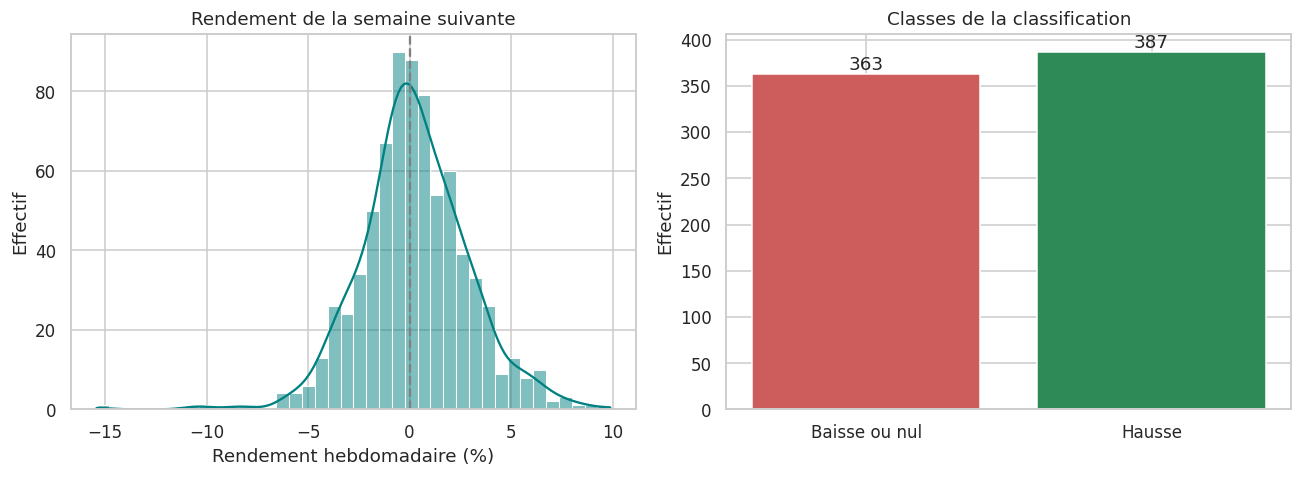

In [ ]:
# Distribution du rendement de la semaine suivante et effectifs des deux classes
rendement_suivant = "percent_change_next_weeks_price"
df["hausse_suivante"] = (df[rendement_suivant] > 0).astype(int)

print(f"Rendement de la semaine suivante : moyenne = {df[rendement_suivant].mean():.2f} %, "
      f"écart-type = {df[rendement_suivant].std():.2f} %")
print(f"Part des semaines suivantes en hausse : {df['hausse_suivante'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df[rendement_suivant].dropna(), bins=40, kde=True, color="teal", ax=axes[0])
axes[0].axvline(0, color="grey", linestyle="--")
axes[0].set_title("Rendement de la semaine suivante")
axes[0].set_xlabel("Rendement hebdomadaire (%)")
axes[0].set_ylabel("Effectif")

effectifs = df["hausse_suivante"].value_counts().reindex([0, 1], fill_value=0)
axes[1].bar(["Baisse ou nul", "Hausse"], effectifs.values, color=["indianred", "seagreen"])
for i, v in enumerate(effectifs.values):
    axes[1].text(i, v, f"{v}", ha="center", va="bottom")
axes[1].set_title("Classes de la classification")
axes[1].set_ylabel("Effectif")
plt.tight_layout()
plt.show()

**Lecture.** Comparez la moyenne à zéro et à l'écart-type affichés : un rendement moyen faible devant l'écart-type signifie que la plus grande part de la variation est du bruit, ce qui limite d'avance ce qu'un modèle peut espérer. La part de semaines en hausse indique le niveau de la **référence de classification** : une part proche de 50 % donne une classe majoritaire peu dominante, une part nettement plus élevée rend l'exactitude facile à atteindre sans aucun apprentissage. Nous suivrons donc aussi la ROC-AUC et la PR-AUC, qui ne dépendent pas d'un seuil.

### 4.2 Rendements hebdomadaires selon le titre

Une boîte à moustaches par titre montre si certains titres sont plus volatils ou plus rentables que d'autres sur la période.

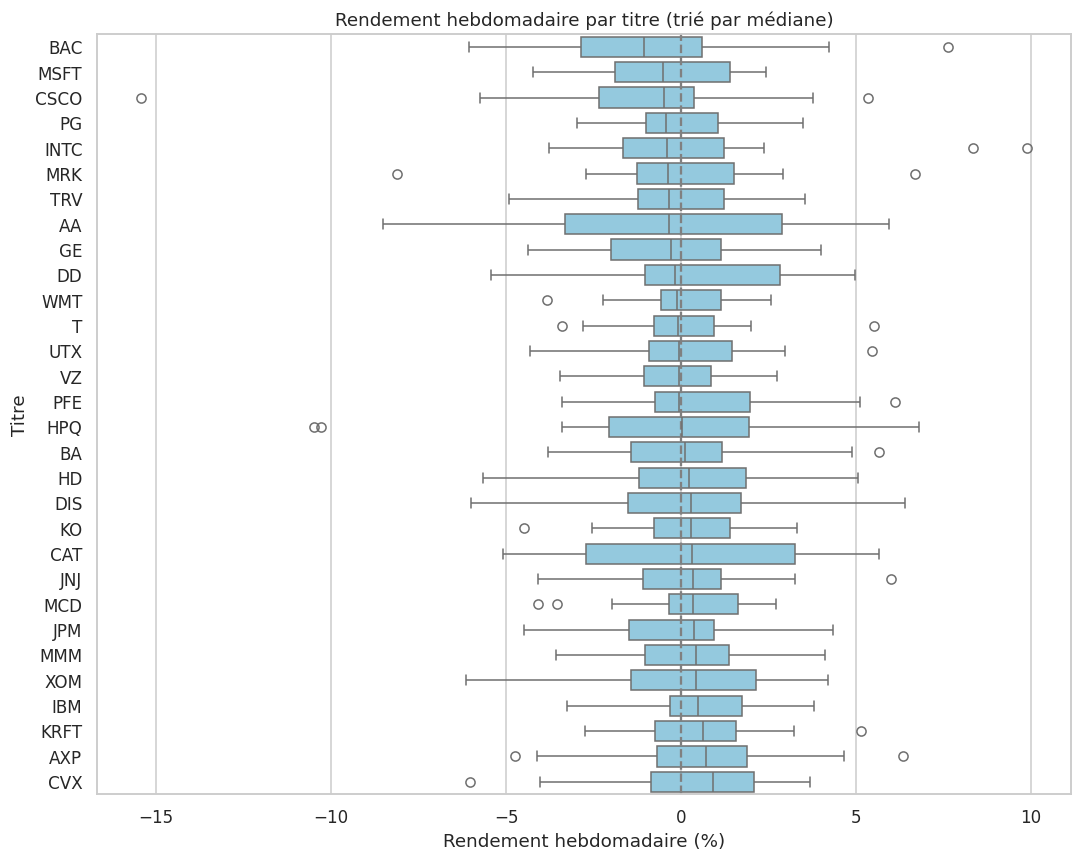

In [ ]:
# Boîtes à moustaches du rendement hebdomadaire, une par titre
ordre = df.groupby("stock")["percent_change_price"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(data=df, y="stock", x="percent_change_price", order=ordre, color="skyblue", ax=ax)
ax.axvline(0, color="grey", linestyle="--")
ax.set_title("Rendement hebdomadaire par titre (trié par médiane)")
ax.set_xlabel("Rendement hebdomadaire (%)")
ax.set_ylabel("Titre")
plt.tight_layout()
plt.show()

**Lecture.** Les écarts de médiane entre titres sont faibles devant la dispersion à l'intérieur de chaque titre : sur seulement 25 semaines, on ne peut pas affirmer qu'un titre est durablement meilleur qu'un autre. Les largeurs de boîte diffèrent en revanche d'un titre à l'autre : certains titres sont structurellement plus volatils, ce qui compte pour l'erreur quadratique.

### 4.3 Les titres bougent-ils ensemble ?

On calcule, pour chaque semaine, le rendement moyen des 30 titres et la part de titres en hausse. Si les titres évoluent tous dans le même sens, les 30 observations d'une même semaine ne sont pas indépendantes.

Semaine au plus faible rendement moyen : 2011-06-03 (-3.26 %, 0% de titres en hausse)


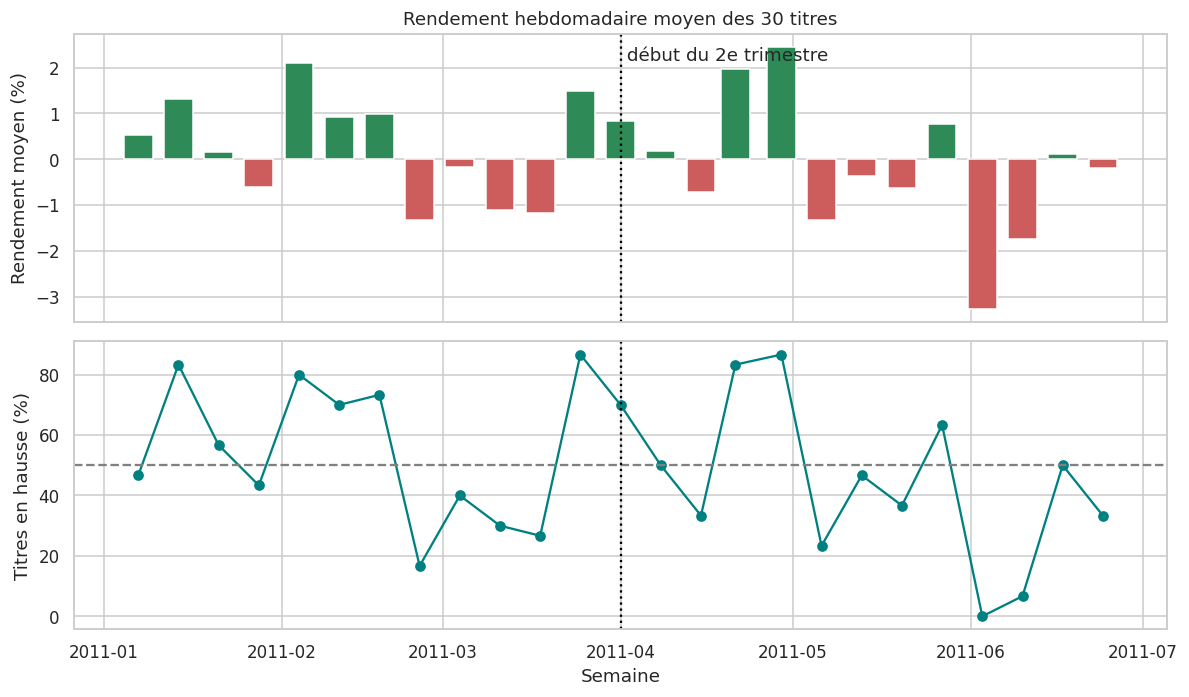

In [ ]:
# Rendement moyen et part de titres en hausse, semaine par semaine
par_semaine = df.groupby("date").agg(
    rendement_moyen=("percent_change_price", "mean"),
    part_hausse=("percent_change_price", lambda s: (s > 0).mean()),
)
debut_t2 = df.loc[df["quarter"] == 2, "date"].min()
pire_semaine = par_semaine["rendement_moyen"].idxmin()
print(f"Semaine au plus faible rendement moyen : {pire_semaine.date()} "
      f"({par_semaine.loc[pire_semaine, 'rendement_moyen']:.2f} %, "
      f"{par_semaine.loc[pire_semaine, 'part_hausse']:.0%} de titres en hausse)")

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
couleurs = np.where(par_semaine["rendement_moyen"] >= 0, "seagreen", "indianred")
axes[0].bar(par_semaine.index, par_semaine["rendement_moyen"], width=5, color=couleurs)
axes[0].set_ylabel("Rendement moyen (%)")
axes[0].set_title("Rendement hebdomadaire moyen des 30 titres")
axes[1].plot(par_semaine.index, par_semaine["part_hausse"] * 100, "o-", color="teal")
axes[1].axhline(50, color="grey", linestyle="--")
axes[1].set_ylabel("Titres en hausse (%)")
axes[1].set_xlabel("Semaine")
for ax in axes:
    ax.axvline(debut_t2, color="black", linestyle=":")
axes[0].text(debut_t2, axes[0].get_ylim()[1] * 0.9, " début du 2e trimestre", va="top")
plt.tight_layout()
plt.show()

**Lecture.** La documentation du jeu de données signale qu'au cours de la semaine se terminant le 27 mai 2011, tous les titres ont perdu de l'argent. Les graphiques le confirment si la part de titres en hausse tombe près de 0 % cette semaine-là. Conséquence importante : les rendements des 30 titres sont fortement liés par un **facteur de marché** commun. Les 30 observations d'une même semaine ne sont pas indépendantes, et la taille effective de l'échantillon est plus proche du nombre de semaines (25) que de 750. Les scores que nous calculerons plus loin sont donc **bruités**, et les écarts faibles entre modèles seront difficiles à distinguer du hasard.

### 4.4 Relation entre le rendement courant et le rendement suivant

Le nuage de points croise le rendement de la semaine et celui de la semaine suivante. La matrice de corrélation résume les liens linéaires entre variables numériques.

Corrélation de Pearson  : 0.020
Corrélation de Spearman : 0.029


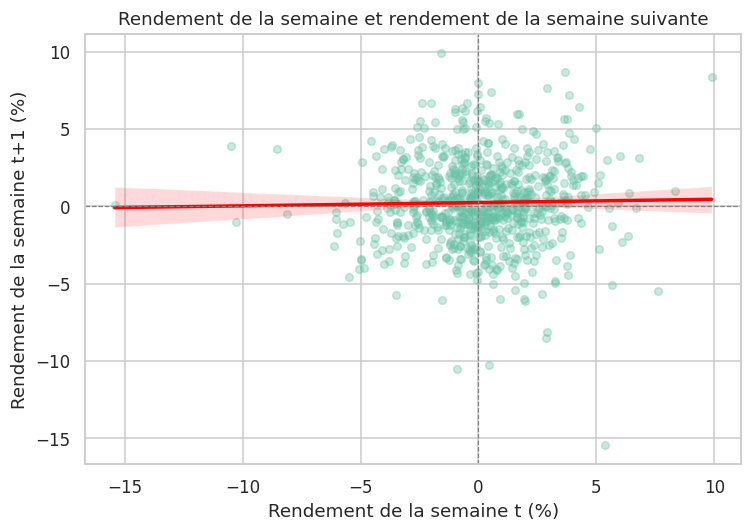

In [ ]:
# Rendement de la semaine (t) contre rendement de la semaine suivante (t+1)
r_pearson = df["percent_change_price"].corr(df[rendement_suivant])
r_spearman = df["percent_change_price"].corr(df[rendement_suivant], method="spearman")
print(f"Corrélation de Pearson  : {r_pearson:.3f}")
print(f"Corrélation de Spearman : {r_spearman:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df, x="percent_change_price", y=rendement_suivant,
            scatter_kws={"alpha": 0.35, "s": 25}, line_kws={"color": "red"}, ax=ax)
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Rendement de la semaine et rendement de la semaine suivante")
ax.set_xlabel("Rendement de la semaine t (%)")
ax.set_ylabel("Rendement de la semaine t+1 (%)")
plt.tight_layout()
plt.show()

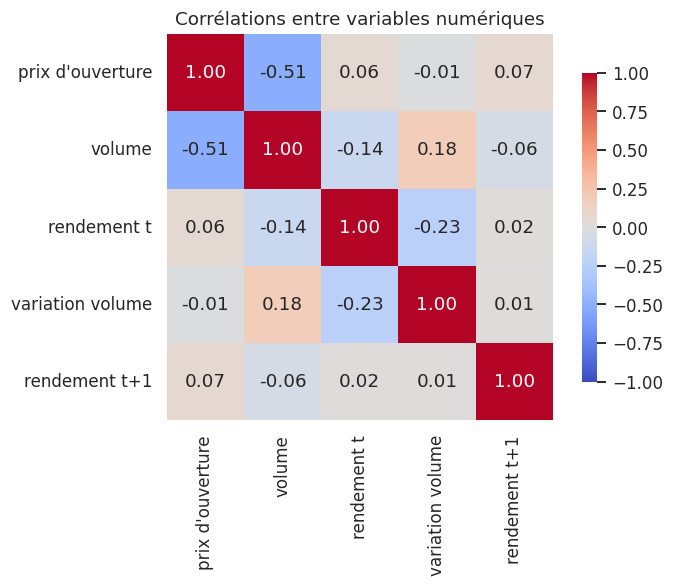

In [ ]:
# Matrice de corrélation (noms abrégés pour la lisibilité)
noms_courts = {
    "open": "prix d'ouverture", "volume": "volume",
    "percent_change_price": "rendement t",
    "percent_change_volume_over_last_wk": "variation volume",
    rendement_suivant: "rendement t+1",
}
corr = df[list(noms_courts)].rename(columns=noms_courts).corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

**Lecture.** Une corrélation proche de 0 (de l'ordre de quelques centièmes en valeur absolue) entre le rendement de la semaine et celui de la suivante ne se distingue pas du bruit : la droite rouge est alors presque horizontale et le nuage n'a pas de structure visible. C'est le résultat attendu si le marché est efficient. Une corrélation nettement positive indiquerait une **tendance** (momentum), une corrélation négative un **retour à la moyenne**. Dans la matrice, regardez aussi le lien entre `prix d'ouverture` et les autres variables : le niveau de prix identifie en pratique le titre (un titre à 160 \$ n'est jamais confondu avec un titre à 15 \$), ce qui en fait un indicateur indirect de l'identité du titre plutôt qu'une information sur sa dynamique.

## 5. Préparation des données

Règles à respecter :

- **Aucune information future dans les variables explicatives.** Pour prédire le rendement de la semaine $t+1$, on n'utilise que ce qui est connu à la clôture de la semaine $t$. Les variables `next_weeks_open`, `next_weeks_close` et `percent_change_next_weeks_price` appartiennent à la semaine à prévoir : elles sont exclues. Les variables de dividende (`days_to_next_dividend`, `percent_return_next_dividend`) sont écartées du modèle de base et reprises dans les questions de fin de projet.
- **Variables décalées calculées titre par titre.** Le rendement de la semaine précédente d'un titre ne doit jamais être celui d'un autre titre : les décalages se font à l'intérieur de chaque titre.
- **Découpage chronologique.** On apprend sur le 1er trimestre et on teste sur le 2e : un découpage aléatoire mélangerait passé et futur et gonflerait artificiellement les scores. La cible de la dernière semaine du 1er trimestre est le rendement de la première semaine du 2e : on retire cette semaine de l'apprentissage (**embargo** d'une semaine).
- **Standardiser sans fuite.** La moyenne et l'écart-type sont appris sur l'entraînement uniquement, à l'intérieur d'un `Pipeline`.

### 5.1 Vérification de la cible

In [ ]:
# La cible fournie (semaine t+1) doit coïncider avec le rendement de la ligne suivante du même titre
suivant_reel = df.groupby("stock")["percent_change_price"].shift(-1)
ecart = (df[rendement_suivant] - suivant_reel).abs().dropna()
print(f"Écart absolu maximal : {ecart.max():.4f} point(s) de pourcentage")
print(f"Part des lignes avec un écart inférieur à 0,05 : {(ecart < 0.05).mean():.1%}")

Écart absolu maximal : 0.0000 point(s) de pourcentage
Part des lignes avec un écart inférieur à 0,05 : 100.0%


**Lecture.** Un écart maximal très faible (arrondis près) confirme que la cible fournie est bien le rendement observé la semaine suivante, calculé uniquement à partir de prix postérieurs à la semaine $t$ : elle ne contient pas d'information sur le passé qui fausserait l'apprentissage. Si quelques lignes s'écartent nettement, il faut les examiner avant de poursuivre.

### 5.2 Variables explicatives, cible et découpage

In [ ]:
# 1) Variables explicatives, toutes connues à la clôture de la semaine t
df["ret"] = df["percent_change_price"]
df["ret_lag1"] = df.groupby("stock")["ret"].shift(1)      # rendement de la semaine t-1
df["ret_lag2"] = df.groupby("stock")["ret"].shift(2)      # rendement de la semaine t-2
df["amplitude"] = (df["high"] - df["low"]) / df["open"] * 100   # écart haut-bas de la semaine (%)
df["variation_volume"] = df["percent_change_volume_over_last_wk"]
df["log_volume"] = np.log(df["volume"])

variables_explicatives = ["open", "ret", "ret_lag1", "ret_lag2",
                          "amplitude", "variation_volume", "log_volume"]

# 2) Cibles : régression (rendement t+1) et classification (hausse en t+1)
df["y_reg"] = df[rendement_suivant]
df["y_clf"] = (df["y_reg"] > 0).astype(int)

# 3) Lignes utilisables : variables décalées disponibles et cible connue
data = df.dropna(subset=variables_explicatives + ["y_reg"]).reset_index(drop=True)
print("Observations utilisables :", len(data), "sur", len(df))

# 4) Découpage chronologique : 1er trimestre -> apprentissage, 2e trimestre -> test
derniere_semaine_t1 = data.loc[data["quarter"] == 1, "date"].max()
est_test = data["quarter"] == 2
est_embargo = data["date"] == derniere_semaine_t1
est_train = (data["quarter"] == 1) & ~est_embargo

X_train = data.loc[est_train, variables_explicatives].reset_index(drop=True)
X_test = data.loc[est_test, variables_explicatives].reset_index(drop=True)
y_train_reg = data.loc[est_train, "y_reg"].reset_index(drop=True)
y_test_reg = data.loc[est_test, "y_reg"].reset_index(drop=True)
y_train_clf = data.loc[est_train, "y_clf"].reset_index(drop=True)
y_test_clf = data.loc[est_test, "y_clf"].reset_index(drop=True)
dates_train = data.loc[est_train, "date"].reset_index(drop=True)
meta_test = data.loc[est_test, ["stock", "date"]].reset_index(drop=True)

print(f"Entraînement : {len(X_train)} observations, {dates_train.nunique()} semaines "
      f"({dates_train.min().date()} -> {dates_train.max().date()})")
print(f"Test         : {len(X_test)} observations, {meta_test['date'].nunique()} semaines "
      f"({meta_test['date'].min().date()} -> {meta_test['date'].max().date()})")
print(f"Embargo      : semaine du {derniere_semaine_t1.date()} retirée de l'apprentissage")
print(f"Part de hausses : entraînement {y_train_clf.mean():.1%} | test {y_test_clf.mean():.1%}")

Observations utilisables : 690 sur 750
Entraînement : 270 observations, 9 semaines (2011-01-21 -> 2011-03-18)
Test         : 390 observations, 13 semaines (2011-04-01 -> 2011-06-24)
Embargo      : semaine du 2011-03-25 retirée de l'apprentissage
Part de hausses : entraînement 51.9% | test 47.2%


**Lecture.** L'apprentissage ne repose que sur quelques semaines : après le retrait des premières semaines (variables décalées indisponibles) et de la semaine d'embargo, il reste environ 9 semaines du 1er trimestre. C'est une **limite structurelle** du jeu de données, qui conditionnera la fiabilité de toutes les conclusions. Comparez aussi la part de hausses entre entraînement et test : un écart important est le signe d'une **dérive temporelle** (le marché n'a pas le même comportement d'une période à l'autre), qui pénalise toute règle apprise sur le passé.

## 6. Entraînement et comparaison de modèles

### 6.1 Principe de la comparaison

Nous comparons des modèles du plus simple au plus complexe, en partant de **références** qui ignorent complètement les variables explicatives :

- *régression* : prédire toujours un rendement nul, ou toujours le rendement moyen de l'entraînement (« moyenne historique ») ;
- *classification* : prédire toujours la classe majoritaire de l'entraînement, avec pour probabilité sa fréquence.

Tout modèle utile doit faire mieux que ces références. Les modèles appris sont une régression linéaire (ou logistique) et une forêt aléatoire, dont les arbres sont volontairement peu profonds (`min_samples_leaf=10`) pour limiter le surapprentissage sur une cible très bruitée.

### 6.2 Validation « en marche avant »

La validation croisée aléatoire est interdite ici : elle apprendrait sur des semaines postérieures aux semaines de validation. On utilise une validation **en marche avant** : à chaque pli, on apprend sur les premières semaines et on valide sur les semaines suivantes, avec une semaine d'écart (`gap=1`) pour la même raison que l'embargo. Toutes les observations d'une même semaine restent dans le même ensemble.

In [ ]:
# Validation chronologique en marche avant, définie sur les semaines
def decoupage_chrono(dates, n_splits=3, gap=1):
    semaines = pd.Index(dates.unique()).sort_values()
    for idx_app, idx_val in TimeSeriesSplit(n_splits=n_splits, gap=gap).split(semaines):
        yield (np.where(dates.isin(semaines[idx_app]))[0],
               np.where(dates.isin(semaines[idx_val]))[0])

cv = list(decoupage_chrono(dates_train, n_splits=3, gap=1))
for i, (app, val) in enumerate(cv, 1):
    print(f"Pli {i} : {dates_train.iloc[app].nunique()} semaines d'apprentissage "
          f"-> {dates_train.iloc[val].nunique()} semaines de validation")

# Modèles de régression, chacun précédé de la même standardisation
def avec_echelle(modele):
    return Pipeline([("echelle", StandardScaler()), ("modele", modele)])

pipes_reg = {
    "Référence (rendement nul)": avec_echelle(DummyRegressor(strategy="constant", constant=0.0)),
    "Référence (moyenne historique)": avec_echelle(DummyRegressor(strategy="mean")),
    "Régression linéaire": avec_echelle(LinearRegression()),
    "Forêt aléatoire": avec_echelle(RandomForestRegressor(
        n_estimators=300, min_samples_leaf=10, max_features=0.5, random_state=42, n_jobs=-1)),
}

# Modèles de classification
pipes_clf = {
    "Référence (classe majoritaire)": avec_echelle(DummyClassifier(strategy="prior")),
    "Régression logistique": avec_echelle(LogisticRegression(max_iter=1000)),
    "Forêt aléatoire": avec_echelle(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=10, max_features=0.5, random_state=42, n_jobs=-1)),
}

Pli 1 : 2 semaines d'apprentissage -> 2 semaines de validation
Pli 2 : 4 semaines d'apprentissage -> 2 semaines de validation
Pli 3 : 6 semaines d'apprentissage -> 2 semaines de validation


In [ ]:
# Fonctions d'évaluation et de validation croisée
def evaluer_reg(pipe, X, y):
    p = pipe.predict(X)
    return {"RMSE": np.sqrt(mean_squared_error(y, p)),
            "MAE": mean_absolute_error(y, p),
            "Direction": np.mean((np.asarray(y) > 0) == (p > 0))}

def evaluer_clf(pipe, X, y):
    proba = pipe.predict_proba(X)[:, 1]
    try:
        roc = roc_auc_score(y, proba)
    except ValueError:
        roc = np.nan
    return {"ROC-AUC": roc,
            "PR-AUC": average_precision_score(y, proba),
            "Exactitude": accuracy_score(y, pipe.predict(X))}

def validation_croisee(pipelines, X, y, cv, evaluer):
    lignes = []
    for nom, pipe in pipelines.items():
        resultats = []
        for idx_app, idx_val in cv:
            pipe.fit(X.iloc[idx_app], y.iloc[idx_app])
            resultats.append(evaluer(pipe, X.iloc[idx_val], y.iloc[idx_val]))
        res = pd.DataFrame(resultats)
        ligne = {"Modèle": nom}
        for c in res.columns:
            ligne[f"{c} (moy.)"] = res[c].mean()
            ligne[f"{c} (écart-type)"] = res[c].std()
        lignes.append(ligne)
    return pd.DataFrame(lignes)

tab_reg = validation_croisee(pipes_reg, X_train, y_train_reg, cv, evaluer_reg).sort_values("RMSE (moy.)")
tab_reg.round(3)

,Modèle,RMSE (moy.),RMSE (écart-type),MAE (moy.),MAE (écart-type),Direction (moy.),Direction (écart-type)
0,Référence (rendement nul),2.155,0.340,1.664,0.307,0.544,0.108
1,Référence (moyenne historique),2.364,0.130,1.871,0.091,0.456,0.108
3,Forêt aléatoire,2.386,0.066,1.855,0.166,0.483,0.117
2,Régression linéaire,2.469,0.118,1.959,0.155,0.494,0.125


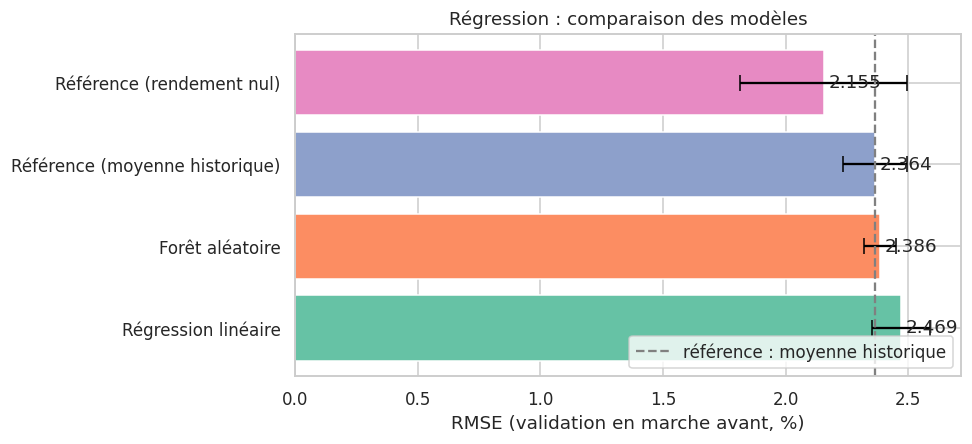

Meilleur modèle appris (RMSE de validation le plus bas) : Forêt aléatoire


In [ ]:
# Régression : RMSE en validation croisée, avec barres d'erreur
fig, ax = plt.subplots(figsize=(9, 4.2))
tab = tab_reg.sort_values("RMSE (moy.)", ascending=False)
ax.barh(tab["Modèle"], tab["RMSE (moy.)"], xerr=tab["RMSE (écart-type)"], capsize=5,
        color=sns.color_palette("Set2", len(tab)))
niveau_ref = tab_reg.loc[tab_reg["Modèle"] == "Référence (moyenne historique)", "RMSE (moy.)"].iloc[0]
ax.axvline(niveau_ref, color="grey", linestyle="--", label="référence : moyenne historique")
for i, val in enumerate(tab["RMSE (moy.)"]):
    ax.text(val + 0.02, i, f"{val:.3f}", va="center")
ax.set_xlabel("RMSE (validation en marche avant, %)")
ax.set_title("Régression : comparaison des modèles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

meilleur_reg = tab_reg[~tab_reg["Modèle"].str.startswith("Référence")].iloc[0]["Modèle"]
print("Meilleur modèle appris (RMSE de validation le plus bas) :", meilleur_reg)

**Lecture.** Les deux références fixent le niveau à battre. Un modèle n'apporte quelque chose que si son RMSE est **nettement** inférieur à celui de la moyenne historique, c'est-à-dire d'un écart supérieur à l'écart-type entre plis (barres d'erreur). Avec trois plis très courts, ces écarts-types sont grands : un classement serré entre deux modèles n'est pas significatif. Un RMSE supérieur à celui de la référence signale un **surapprentissage** : le modèle a appris du bruit propre à la période d'entraînement. La précision de direction de la référence « rendement nul » équivaut à toujours prédire une baisse : elle sert de point de repère, non de modèle sérieux.

,Modèle,ROC-AUC (moy.),ROC-AUC (écart-type),PR-AUC (moy.),PR-AUC (écart-type),Exactitude (moy.),Exactitude (écart-type)
1,Régression logistique,0.615,0.081,0.585,0.128,0.533,0.159
2,Forêt aléatoire,0.606,0.076,0.528,0.145,0.511,0.142
0,Référence (classe majoritaire),0.500,0.000,0.456,0.108,0.456,0.108


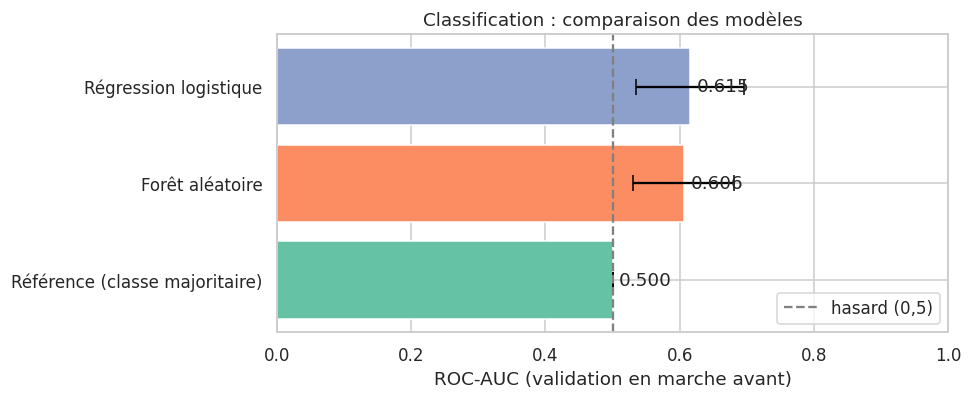

Meilleur modèle appris (ROC-AUC de validation la plus haute) : Régression logistique


In [ ]:
# Classification : validation en marche avant
tab_clf = validation_croisee(pipes_clf, X_train, y_train_clf, cv, evaluer_clf).sort_values("ROC-AUC (moy.)", ascending=False)
display(tab_clf.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
tab = tab_clf.sort_values("ROC-AUC (moy.)", ascending=True)
ax.barh(tab["Modèle"], tab["ROC-AUC (moy.)"], xerr=tab["ROC-AUC (écart-type)"], capsize=5,
        color=sns.color_palette("Set2", len(tab)))
ax.axvline(0.5, color="grey", linestyle="--", label="hasard (0,5)")
for i, val in enumerate(tab["ROC-AUC (moy.)"]):
    ax.text(val + 0.01, i, f"{val:.3f}", va="center")
ax.set_xlim(0, 1)
ax.set_xlabel("ROC-AUC (validation en marche avant)")
ax.set_title("Classification : comparaison des modèles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

meilleur_clf = tab_clf[~tab_clf["Modèle"].str.startswith("Référence")].iloc[0]["Modèle"]
print("Meilleur modèle appris (ROC-AUC de validation la plus haute) :", meilleur_clf)

**Lecture.** Une ROC-AUC de 0,5 correspond au hasard : le modèle ne classe pas mieux les semaines en hausse devant les semaines en baisse. La PR-AUC doit se comparer à la **proportion de hausses** (la PR-AUC d'un classifieur sans pouvoir de discrimination est égale à cette proportion), et non à 0,5. Là encore, regardez l'écart-type entre plis avant d'interpréter une différence de quelques centièmes.

## 7. Évaluation finale sur le jeu de test

Les modèles sont entraînés sur tout l'ensemble d'entraînement, puis évalués **une seule fois** sur le 2e trimestre. Ce score estime la performance sur des semaines réellement postérieures à l'apprentissage.

### 7.1 Régression

En plus du RMSE et de la MAE, on calcule le **R² hors échantillon** par rapport à la moyenne historique :

$$R^2_{\text{hors éch.}} = 1 - \frac{\sum (y - \hat y_{\text{modèle}})^2}{\sum (y - \hat y_{\text{moyenne historique}})^2}$$

Il est positif si le modèle prédit mieux que la moyenne historique, négatif sinon.

In [ ]:
# Entraînement sur tout l'apprentissage, évaluation sur le test
pred_test = {}
for nom, pipe in pipes_reg.items():
    pipe.fit(X_train, y_train_reg)
    pred_test[nom] = pipe.predict(X_test)

mse_ref = mean_squared_error(y_test_reg, pred_test["Référence (moyenne historique)"])
lignes = []
for nom, p in pred_test.items():
    lignes.append({
        "Modèle": nom,
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, p)),
        "MAE": mean_absolute_error(y_test_reg, p),
        "Direction": np.mean((y_test_reg.values > 0) == (p > 0)),
        "R² hors échantillon": 1 - mean_squared_error(y_test_reg, p) / mse_ref,
    })
res_reg = pd.DataFrame(lignes).set_index("Modèle")
res_reg.round(3)

,RMSE,MAE,Direction,R² hors échantillon
Modèle,,,,
Référence (rendement nul),2.843,2.139,0.528,-0.004
Référence (moyenne historique),2.837,2.148,0.472,0.000
Régression linéaire,2.835,2.170,0.495,0.002
Forêt aléatoire,2.907,2.202,0.482,-0.050


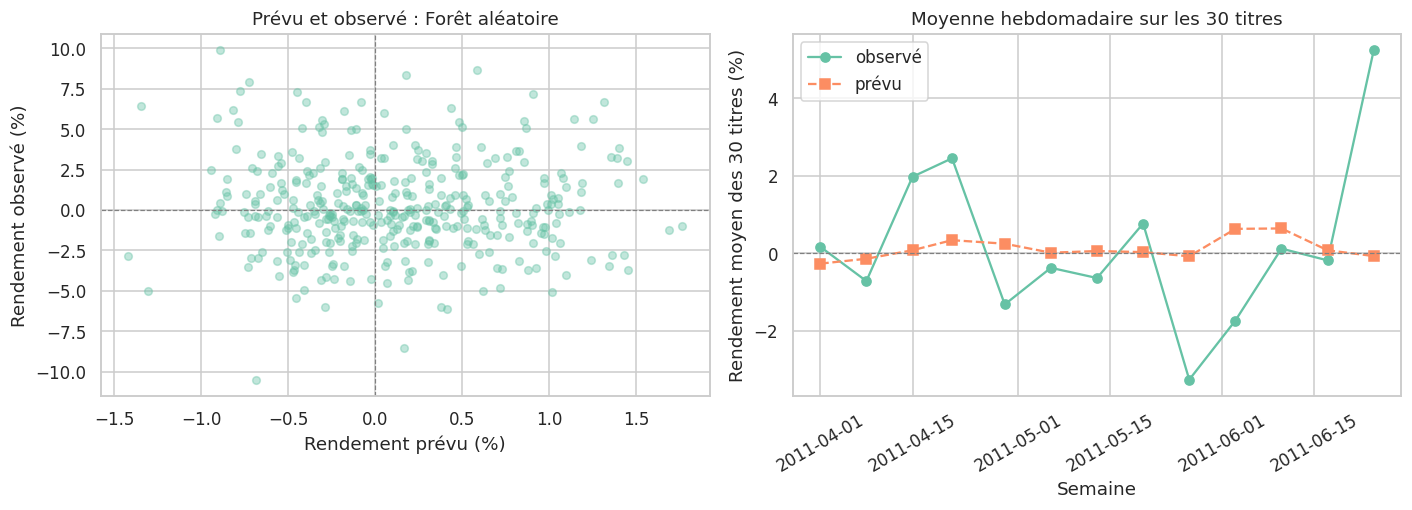

In [ ]:
# Prévu contre réel (observation par observation) et moyenne hebdomadaire sur les 30 titres
p_best = pred_test[meilleur_reg]
meta = meta_test.copy()
meta["reel"], meta["prevu"] = y_test_reg.values, p_best
hebdo = meta.groupby("date")[["reel", "prevu"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(p_best, y_test_reg, alpha=0.4, s=25)
axes[0].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[0].axvline(0, color="grey", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("Rendement prévu (%)")
axes[0].set_ylabel("Rendement observé (%)")
axes[0].set_title(f"Prévu et observé : {meilleur_reg}")

axes[1].plot(hebdo.index, hebdo["reel"], "o-", label="observé")
axes[1].plot(hebdo.index, hebdo["prevu"], "s--", label="prévu")
axes[1].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[1].set_xlabel("Semaine")
axes[1].set_ylabel("Rendement moyen des 30 titres (%)")
axes[1].set_title("Moyenne hebdomadaire sur les 30 titres")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Lecture.** Comparez le RMSE du meilleur modèle à celui de la moyenne historique et regardez le signe du R² hors échantillon : un R² négatif ou voisin de zéro signifie que le modèle ne bat pas la référence, ce qui est le résultat le plus courant pour des rendements hebdomadaires. En finance, un R² hors échantillon de l'ordre de 1 % serait déjà considéré comme notable. Dans le nuage de gauche, un modèle sans pouvoir prédictif donne des prévisions regroupées près de zéro, sans lien visible avec l'axe vertical. Dans le graphique de droite, observez si les prévisions suivent les grands mouvements **communs à tous les titres** : ces mouvements de marché (comme la semaine de baisse généralisée) sont ceux qui dominent l'erreur, et ils ne sont pas prévisibles à partir des seuls rendements passés d'un titre.

### 7.2 La direction est-elle mieux prévue que par la référence ?

On compare la proportion de directions correctement prédites à celle d'une référence qui annonce toujours la classe majoritaire de l'entraînement. Un test binomial indique si l'écart pourrait s'expliquer par le hasard.

In [ ]:
# Précision de direction du meilleur modèle de régression contre la référence majoritaire
classe_ref = int(y_train_clf.mean() >= 0.5)
acc_ref = float(np.mean(y_test_clf.values == classe_ref))
bonnes = int(np.sum((p_best > 0) == (y_test_reg.values > 0)))
n_test = len(y_test_reg)
acc_modele = bonnes / n_test
test_dir = binomtest(bonnes, n_test, p=acc_ref, alternative="greater")

print(f"Référence (toujours « {'hausse' if classe_ref else 'baisse'} ») : {acc_ref:.1%}")
print(f"{meilleur_reg} : {acc_modele:.1%} ({bonnes} bonnes directions sur {n_test})")
print(f"Test binomial unilatéral : p = {test_dir.pvalue:.3f}")

Référence (toujours « hausse ») : 47.2%
Forêt aléatoire : 48.2% (188 bonnes directions sur 390)
Test binomial unilatéral : p = 0.361


**Lecture.** Une p-valeur élevée (par exemple au-dessus de 0,05) signifie que la précision de direction du modèle ne se distingue pas de celle de la référence. Ce test est même **trop favorable au modèle** : il suppose les observations indépendantes, alors que les 30 titres d'une même semaine évoluent ensemble (section 4.3). La p-valeur réelle serait plus élevée encore. Une p-valeur faible devrait donc être confirmée par d'autres périodes avant d'être prise au sérieux.

### 7.3 Classification : matrice de confusion, courbes ROC et précision-rappel

In [ ]:
# Entraînement et évaluation des modèles de classification sur le test
lignes = []
for nom, pipe in pipes_clf.items():
    pipe.fit(X_train, y_train_clf)
    lignes.append({"Modèle": nom, **evaluer_clf(pipe, X_test, y_test_clf)})
res_clf = pd.DataFrame(lignes).set_index("Modèle")
print(f"Proportion de hausses dans le test (PR-AUC d'un classifieur sans pouvoir) : {y_test_clf.mean():.3f}")
display(res_clf.round(3))

pipe_clf = pipes_clf[meilleur_clf]
y_pred_clf = pipe_clf.predict(X_test)
print("\nRapport de classification :", meilleur_clf)
print(classification_report(y_test_clf, y_pred_clf, target_names=["Baisse ou nul", "Hausse"], zero_division=0))

Proportion de hausses dans le test (PR-AUC d'un classifieur sans pouvoir) : 0.472


,ROC-AUC,PR-AUC,Exactitude
Modèle,,,
Référence (classe majoritaire),0.500,0.472,0.472
Régression logistique,0.539,0.533,0.510
Forêt aléatoire,0.540,0.493,0.526



Rapport de classification : Régression logistique
               precision    recall  f1-score   support

Baisse ou nul       0.55      0.43      0.48       206
       Hausse       0.48      0.60      0.54       184

     accuracy                           0.51       390
    macro avg       0.52      0.52      0.51       390
 weighted avg       0.52      0.51      0.51       390



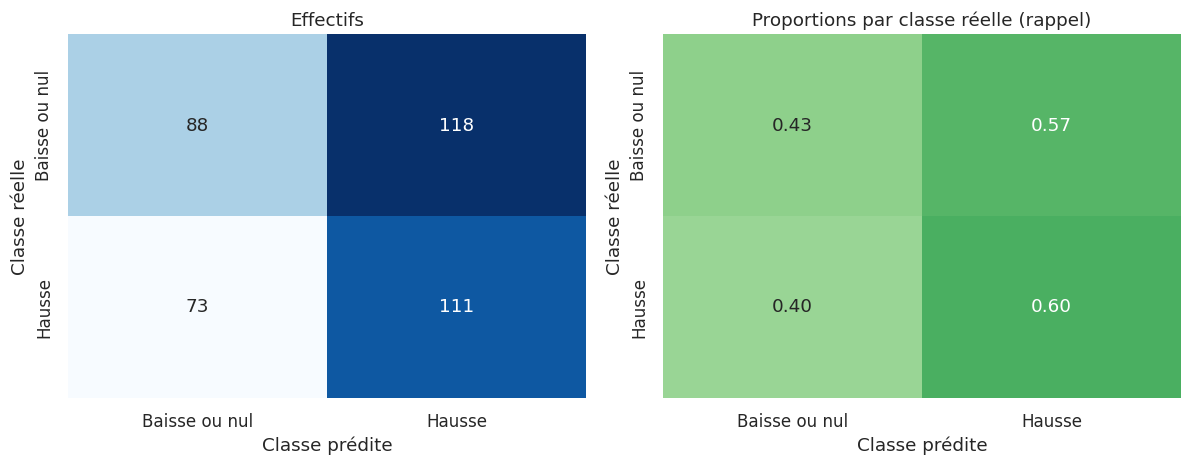

In [ ]:
# Matrice de confusion : effectifs et proportions par ligne (rappel)
classes = ["Baisse ou nul", "Hausse"]
cm = confusion_matrix(y_test_clf, y_pred_clf, labels=[0, 1])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False, ax=axes[0])
axes[0].set_title("Effectifs")
axes[0].set_xlabel("Classe prédite")
axes[0].set_ylabel("Classe réelle")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=classes, yticklabels=classes,
            vmin=0, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Proportions par classe réelle (rappel)")
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

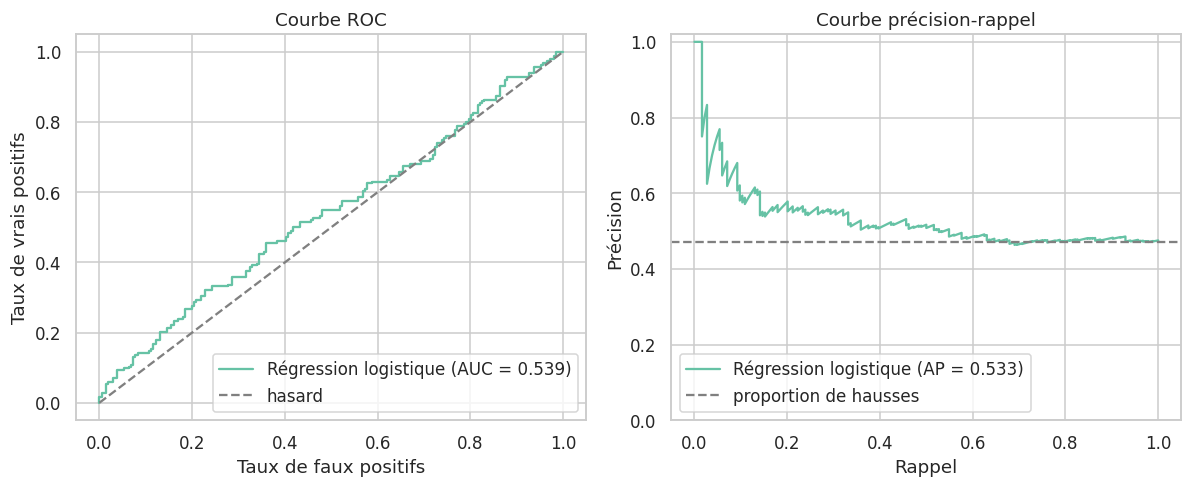

In [ ]:
# Courbes ROC et précision-rappel du meilleur modèle de classification
proba = pipe_clf.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test_clf, proba)
prec, rapp, _ = precision_recall_curve(y_test_clf, proba)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].plot(fpr, tpr, label=f"{meilleur_clf} (AUC = {roc_auc_score(y_test_clf, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="hasard")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs")
axes[0].set_title("Courbe ROC")
axes[0].legend(loc="lower right")

axes[1].plot(rapp, prec, label=f"{meilleur_clf} (AP = {average_precision_score(y_test_clf, proba):.3f})")
axes[1].axhline(y_test_clf.mean(), linestyle="--", color="grey", label="proportion de hausses")
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Courbe précision-rappel")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Lecture.** La matrice de confusion montre **comment** le modèle se trompe, ce que l'exactitude seule cache : un modèle qui prédit presque toujours la classe majoritaire obtient une bonne exactitude mais un rappel très faible sur l'autre classe. Sur la courbe ROC, une courbe confondue avec la diagonale correspond au hasard ; sur la courbe précision-rappel, la ligne pointillée est le niveau d'un classifieur sans pouvoir de discrimination. Une courbe qui ne s'écarte durablement de ces lignes qu'à de rares endroits ne constitue pas un signal exploitable.

## 8. Interprétation du modèle

### 8.1 Importance des variables par permutation

L'importance par permutation mesure de combien le RMSE augmente sur le jeu de test quand on **mélange** aléatoirement les valeurs d'une variable. Une importance proche de zéro (ou négative) indique que la variable n'aide pas à prédire.

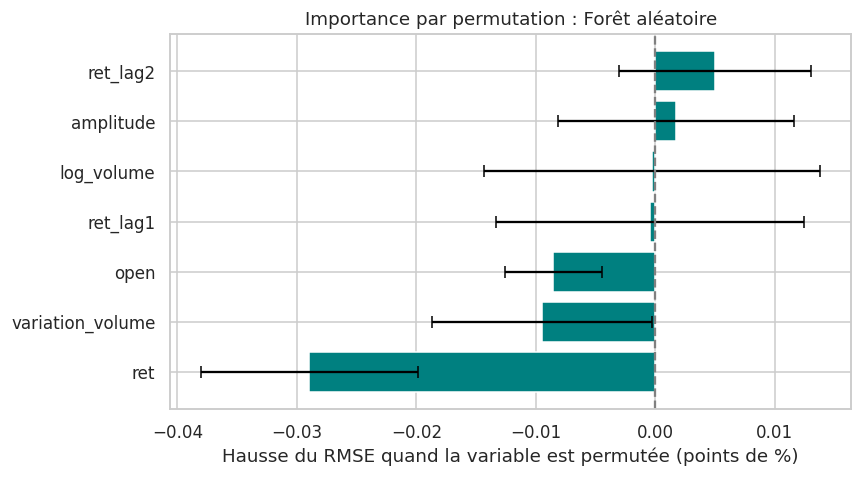

In [ ]:
# Importance par permutation du meilleur modèle de régression (sur le test)
pipe_best = pipes_reg[meilleur_reg]
imp = permutation_importance(pipe_best, X_test, y_test_reg, scoring="neg_root_mean_squared_error",
                             n_repeats=30, random_state=42)
importances = pd.Series(imp.importances_mean, index=variables_explicatives)
ecarts = pd.Series(imp.importances_std, index=variables_explicatives)
ordre = importances.sort_values().index

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(ordre, importances[ordre], xerr=ecarts[ordre], capsize=4, color="teal")
ax.axvline(0, color="grey", linestyle="--")
ax.set_xlabel("Hausse du RMSE quand la variable est permutée (points de %)")
ax.set_title(f"Importance par permutation : {meilleur_reg}")
plt.tight_layout()
plt.show()

**Lecture.** Une variable dont l'importance est plus grande que son écart-type est la seule à mériter l'attention. Méfiez-vous particulièrement de `open` : le niveau du prix identifie le titre, et une importance élevée peut refléter le fait que certains titres ont, par hasard, mieux performé que d'autres pendant le 2e trimestre, et non une relation durable. Comme pour toute mesure d'importance, la corrélation entre variables brouille l'interprétation, et l'importance ne prouve aucune causalité.

### 8.2 Coefficients du modèle linéaire

In [ ]:
# Coefficients de la régression linéaire (variables standardisées : comparables entre elles)
modele_lin = pipes_reg["Régression linéaire"].named_steps["modele"]
coefs = pd.Series(modele_lin.coef_, index=variables_explicatives).sort_values()
print(f"Constante (rendement moyen prédit à variables moyennes) : {modele_lin.intercept_:.3f} %\n")
print(coefs.round(3))

Constante (rendement moyen prédit à variables moyennes) : 0.126 %

log_volume         -0.281
ret_lag1           -0.275
ret_lag2           -0.017
ret                 0.015
open                0.075
variation_volume    0.150
amplitude           0.199
dtype: float64


**Lecture.** Chaque coefficient indique la variation prévue du rendement suivant (en points de pourcentage) pour une variation d'un écart-type de la variable. Une valeur de quelques centièmes de point est négligeable devant un écart-type du rendement de plusieurs points. Un coefficient négatif sur les rendements passés irait dans le sens d'un retour à la moyenne, un coefficient positif dans celui d'une tendance ; ces signes ne doivent être commentés que si le modèle bat réellement la référence.

## 9. Prédire une nouvelle observation

Une fois les modèles validés, on peut les utiliser pour la dernière semaine disponible. Le pipeline applique automatiquement la même standardisation qu'à l'entraînement. Cette prévision illustre la procédure ; elle ne constitue pas un conseil d'investissement.

In [ ]:
# Prévision pour la dernière observation du jeu de test
nouvelle = X_test.iloc[[-1]]
info = meta_test.iloc[-1]
print(f"Titre : {info['stock']} | semaine du {info['date'].date()}")
print(nouvelle.round(2).to_string(index=False))

prevu = pipes_reg[meilleur_reg].predict(nouvelle)[0]
proba_hausse = pipes_clf[meilleur_clf].predict_proba(nouvelle)[0, 1]
print(f"\nRendement prévu de la semaine suivante : {prevu:.2f} %")
print(f"Probabilité de hausse estimée          : {proba_hausse:.1%}")
print(f"Rendement réellement observé           : {y_test_reg.iloc[-1]:.2f} %")

Titre : XOM | semaine du 2011-06-24
 open   ret  ret_lag1  ret_lag2  amplitude  variation_volume  log_volume
78.65 -2.38     -1.23     -1.42       5.52             18.06       18.59

Rendement prévu de la semaine suivante : 1.31 %
Probabilité de hausse estimée          : 60.5%
Rendement réellement observé           : 6.67 %


## 10. Synthèse et discussion

### 10.1 Discussion de la précision des prévisions

La cellule suivante résume automatiquement les résultats obtenus sur le jeu de test.

In [ ]:
# Synthèse automatique des résultats finaux
ref = "Référence (moyenne historique)"
r2 = res_reg.loc[meilleur_reg, "R² hors échantillon"]
print("RÉGRESSION")
print(f"  Meilleur modèle appris : {meilleur_reg}")
print(f"  RMSE test : {res_reg.loc[meilleur_reg, 'RMSE']:.3f} % contre {res_reg.loc[ref, 'RMSE']:.3f} % pour la moyenne historique")
print(f"  R² hors échantillon : {r2:.3f} -> "
      + ("le modèle fait mieux que la moyenne historique" if r2 > 0 else "le modèle ne fait pas mieux que la moyenne historique"))
print(f"  Précision de direction : {acc_modele:.1%} contre {acc_ref:.1%} pour la référence (p = {test_dir.pvalue:.3f})")
print("\nCLASSIFICATION")
print(f"  Meilleur modèle appris : {meilleur_clf}")
print(f"  ROC-AUC test : {res_clf.loc[meilleur_clf, 'ROC-AUC']:.3f} (hasard = 0,500)")
print(f"  PR-AUC test  : {res_clf.loc[meilleur_clf, 'PR-AUC']:.3f} (proportion de hausses = {y_test_clf.mean():.3f})")

RÉGRESSION
  Meilleur modèle appris : Forêt aléatoire
  RMSE test : 2.907 % contre 2.837 % pour la moyenne historique
  R² hors échantillon : -0.050 -> le modèle ne fait pas mieux que la moyenne historique
  Précision de direction : 48.2% contre 47.2% pour la référence (p = 0.361)

CLASSIFICATION
  Meilleur modèle appris : Régression logistique
  ROC-AUC test : 0.539 (hasard = 0,500)
  PR-AUC test  : 0.533 (proportion de hausses = 0.472)


### Ce qu'il faut retenir

1. **Type d'apprentissage** : supervisé, formulé en régression (rendement de la semaine suivante) et en classification binaire (hausse ou non). La cible est connue pour chaque observation.
2. **Démarche** : explorer, construire des variables **sans information future**, découper **chronologiquement** avec embargo, comparer à des références, valider en marche avant, évaluer une seule fois sur le test.
3. **Évaluation** : le RMSE seul ne suffit pas ; on le complète par la MAE, le R² hors échantillon, la précision de direction, la ROC-AUC et la PR-AUC, toujours **rapportés à une référence**.
4. **Conclusion** : la synthèse automatique ci-dessus donne la réponse chiffrée à la question posée en section 1. Le critère de décision est simple : un modèle n'est utile que s'il bat la référence de façon nette, supérieure à la variabilité entre plis.

### Limites

- **Fuite de données.** Elle peut venir des variables de la semaine à prévoir (`next_weeks_open`, `next_weeks_close`), d'un découpage aléatoire qui mélange passé et futur, ou de l'absence d'embargo : la cible d'une semaine est le rendement de la suivante. Ces trois sources sont écartées ici ; il suffit d'en réintroduire une pour obtenir des scores flatteurs et trompeurs (questions 4 et 5).
- **Déséquilibre.** La répartition hausse/baisse n'est pas parfaitement équilibrée, et elle diffère entre entraînement et test : l'exactitude doit être lue avec la ROC-AUC, la PR-AUC et la référence majoritaire.
- **Dérive temporelle.** Le marché n'a pas le même comportement d'un trimestre à l'autre ; une règle apprise sur le 1er trimestre n'a aucune raison de tenir pendant le 2e, ni a fortiori dans une autre année.
- **Représentativité.** Le jeu couvre une seule année (2011), 25 semaines et 30 très grandes entreprises américaines. Les résultats ne se généralisent ni à d'autres périodes, ni à d'autres marchés, ni à des titres plus petits.
- **Biais et dépendance.** Les 30 titres évoluent ensemble : la taille effective de l'échantillon est proche de 25 semaines, et les intervalles de confiance et tests présentés sont trop optimistes. Les titres sont ceux de l'indice à l'époque, ce qui ajoute un biais de sélection. Essayer de nombreux modèles et variables sur un même test crée enfin un risque de **sélection sur le test** : seul le premier résultat est vraiment « hors échantillon ». Les coûts de transaction ne sont pas modélisés.

### Questions

1. Pourquoi la référence « moyenne historique » est-elle indispensable ? Quel R² hors échantillon attendre d'un modèle sans aucun pouvoir prédictif ?
2. Retirez la variable `open` et réentraînez les modèles. Que se passe-t-il ? Pourquoi le niveau du prix peut-il agir comme un identifiant du titre ?
3. Ajoutez `days_to_next_dividend` et `percent_return_next_dividend`, qui sont connues à l'avance. Améliorent-elles les prévisions ? Pourquoi un lien mécanique avec le prix est-il plausible ?
4. Remplacez le découpage chronologique par un découpage aléatoire (`train_test_split` avec mélange). Le score change-t-il ? Pourquoi est-ce trompeur pour une série temporelle ?
5. Supprimez l'embargo d'une semaine (`est_embargo`). Quelle information du test fait alors fuite dans l'apprentissage ?
6. Retirez du test la semaine de baisse généralisée repérée en section 4.3. Les conclusions changent-elles ? Qu'en déduisez-vous sur la fragilité des résultats ?
7. Remplacez la cible par le rendement **relatif au marché** (rendement du titre moins la moyenne des 30 titres la même semaine). Est-il plus ou moins facile à prévoir ? Qu'est-ce que cela change financièrement ?

> **Pour aller plus loin.** Reformulez le problème en classement : parmi les 30 titres, lequel aura le meilleur rendement la semaine suivante ? Quelles métriques (corrélation de rangs, rendement du meilleur titre prédit) utiliseriez-vous ?

In [ ]:
# Enregistrer les tableaux de résultats au format LaTeX
res_reg.round(3).to_latex("tab_resultats_reg.tex")
res_clf.round(3).to_latex("tab_resultats_clf.tex")